# Numerical Exercises 10
### Exercise 10.1

Choose **ONLY ONE** of the two following possibilities:

1. Parallelize with MPI libraries your Genetic Algorithm code in order to solve the TSP by performing a *Genetic Search* with (up to) 11 **parallel GA searches of the optimal path**:
each node should perform an independent GA search, the so-called *Continent*, **but** every $N_{migr}$ generations the *Continents* should exchange their best individuals randomly.

2. Starting from your Genetic Algorithm code implement a **Parallel Tempering algorithm** (Simulated Annealing with many temperatures). Parallelize with MPI libraries your algorithm in order to solve the TSP where each computing node, up to 11, is characterized by a different temperature or a limited set of temperatures (if you need more than 11 temperatures). Use your genetic operators (except crossover) as trial moves for the Metropolis algorithm and **add a trial move that proposes an exchange of paths among adjacent temperatures (nodes)** (see lecture 8 for the acceptance formula). The candidate solution of the TSP will appear on the node with the lowest temperature.
### Exercise 10.2

Apply your parallel code to the TSP problem for 110 italian "capoluoghi di provincia" longitude and latitude coordinates in the *cap_prov_ita.dat* file.

If your choice in Exercise 10.1 is option 1, do you improve with respect using the same number of computing cores but with **independent GA searches** ?

If your choice in Exercise 10.1 is option 2, by using a number of temperatures equal to the number of individuals in your **non-parallel Genetic Algorithm code**, do you "improve" with respect to it?

## **Solution**: Parallel Tempering

The provided C++ code implements a hybrid **Simulated Annealing (SA)** algorithm accelerated by **Message Passing Interface (MPI)**. The architecture utilizes a **Parallel Tempering (Replica Exchange)** technique, where multiple independent Markov Chain Monte Carlo (MCMC) simulations run simultaneously at different temperatures. 

To prevent the search from becoming trapped in local minima, adjacent temperature replicas periodically attempt to exchange their current configurations. The core of this implementation lies in its robust MPI communication protocol, which is specifically designed to prevent deadlocks and race conditions.

#### 1. Node Initialization and Data Broadcasting
To ensure computational efficiency and avoid concurrent read conflicts, only the Master node (`rank == 0`) is responsible for reading the input configuration files. The parameters are then broadcasted to all other nodes using `MPI_Bcast`.

Additionally in `compute_T` method, the algorithm assigns a distinct, geometrically spaced temperature to each node to ensure an optimal overlap of energy distributions between adjacent replicas with the following relation:
$$ T_i = T_{\text{min}} \left( \frac{T_{\text{max}}}{T_{\text{min}}} \right)^{\frac{i}{N-1}} $$
where $N$ is the number of nodes.

#### 2. Replica Exchange and Deadlock Prevention
The most critical phase of the parallel algorithm is the migration step, occurring every `n_migr` iterations.

This code employs three strict architectural patterns to guarantee safe communication:

**A. Alternating Pairings (Even/Odd Turns)**
To prevent overlapping communication requests, the algorithm explicitly divides the exchanges into alternating turns based on the current iteration phase (`turn = i/1000`). 
* In **even turns**, pairs are aligned as $(0,1), (2,3), (4,5)$.
* In **odd turns**, pairs are staggered as $(1,2), (3,4), (5,6)$.

This rigid deterministic topology ensures that a node is exclusively paired with exactly one partner at any given migration step, completely eliminating cyclic dependencies.

```cpp
int turn = i/1000;
if (turn%2 == 0) {
    if (rank%2 == 0) partner = rank + 1;
    else partner = rank - 1;
} else {
    if (rank%2 == 0) partner = rank - 1;
    else partner = rank + 1;
}
if (partner >= size || partner < 0) partner = -1; // Boundary check
```

**B. Asymmetric Handshake Protocol**
Once the pair is established, the nodes must evaluate the Metropolis acceptance probability: $p = \exp(- \Delta \beta \cdot \Delta L)$. 
To avoid both nodes waiting for data simultaneously (a classic deadlock scenario), the code enforces an **asymmetric communication sequence** based on the node's rank ID:

```cpp
if (rank > partner) {
    // The higher rank node acts as the SENDER of energy/beta data
    MPI_Send(my_data, 2, MPI_DOUBLE, partner, 0, MPI_COMM_WORLD);
    // Waits to receive the boolean acceptance result
    MPI_Recv(&is_accepted, 1, MPI_INT, partner, 1, MPI_COMM_WORLD, MPI_STATUS_IGNORE);
} else {
    // The lower rank node acts as the RECEIVER and EVALUATOR
    MPI_Recv(partner_data, 2, MPI_DOUBLE, partner, 0, MPI_COMM_WORLD, MPI_STATUS_IGNORE);
    
    // Metropolis evaluation for the exchange
    double delta[2] = {partner_data[0] - my_data[0], my_data[1] - partner_data[1]}; 
    double product = delta[0]*delta[1];
    if (product < 0.0 || rnd.Rannyu() < exp(-product)) is_accepted = 1; 
    
    // Sends the verdict back to the partner
    MPI_Send(&is_accepted, 1, MPI_INT, partner, 1, MPI_COMM_WORLD);
}
```
By strictly forcing the higher-ranked node to initiate the `MPI_Send` while the lower-ranked node initiates the `MPI_Recv`, the communication flow is perfectly synchronized.

**C. Synchronous State Swapping via `MPI_Sendrecv`**
If the replica exchange is mathematically accepted (`is_accepted == 1`), the nodes must physically swap their chromosome arrays (the city sequence). 
Instead of using separate blocking `MPI_Send` and `MPI_Recv` calls—which would require careful manual ordering or auxiliary buffers to avoid deadlocks—the code utilizes the highly optimized `MPI_Sendrecv` function:

```cpp
if (is_accepted == 1) {
    int old_path[n_cities];
    int new_path[n_cities];
    for (int j{}; j < n_cities; j++) old_path[j] = old_ind.get_gene(j);
    
    // Safe, simultaneous bidirectional array swap
    MPI_Sendrecv(
        old_path, n_cities, MPI_INT, partner, 2, 
        new_path, n_cities, MPI_INT, partner, 2,
        MPI_COMM_WORLD, MPI_STATUS_IGNORE
    );
    
    // Update local individual with the new path
    for (int j{}; j < n_cities; j++) old_ind.set_gene(j, new_path[j]); 
    old_ind.compute_fitness(italy);
    L_old = old_ind.get_fitness();                       
}
```
`MPI_Sendrecv` safely executes a bidirectional exchange in a single step at the MPI middleware level, abstracting away the risk of buffering bottlenecks. Once completed, the lower-temperature node continues exploring the configuration space starting from the newly imported, higher-energy path (or vice versa), thereby escaping potential local minima traps.

### **10.1**

### Annealing Schedule and Parallel Tempering Optimization

To identify the optimal temperature schedule for the Traveling Salesman Problem (TSP) on Italian provincial capitals, several configurations of $T_{\min}$ and $T_{\max}$ were systematically explored across identical optimization setups. 

* **Temperature Parameters:** Across both test environments, the optimal temperature range was identified as $T_{\min} = 0.01$ and $T_{\max} = 20.0$.
* **Simulation Scale:** Each simulation was executed for $5 \times 10^7$ Monte Carlo steps.
* **Replica Exchange:** Parallel Tempering migration attempts were performed every $1{,}000$ steps between adjacent temperature replicas.
* **Node Scaling:** Simulations were tested using $7$ MPI nodes (locally) and $11$ MPI nodes (cluster). The $11$-node implementation achieved a strictly shorter path length ($L$) due to finer temperature spacing between adjacent replicas, which yielded higher exchange acceptance probabilities and enabled the system to escape shallow local minima more effectively.

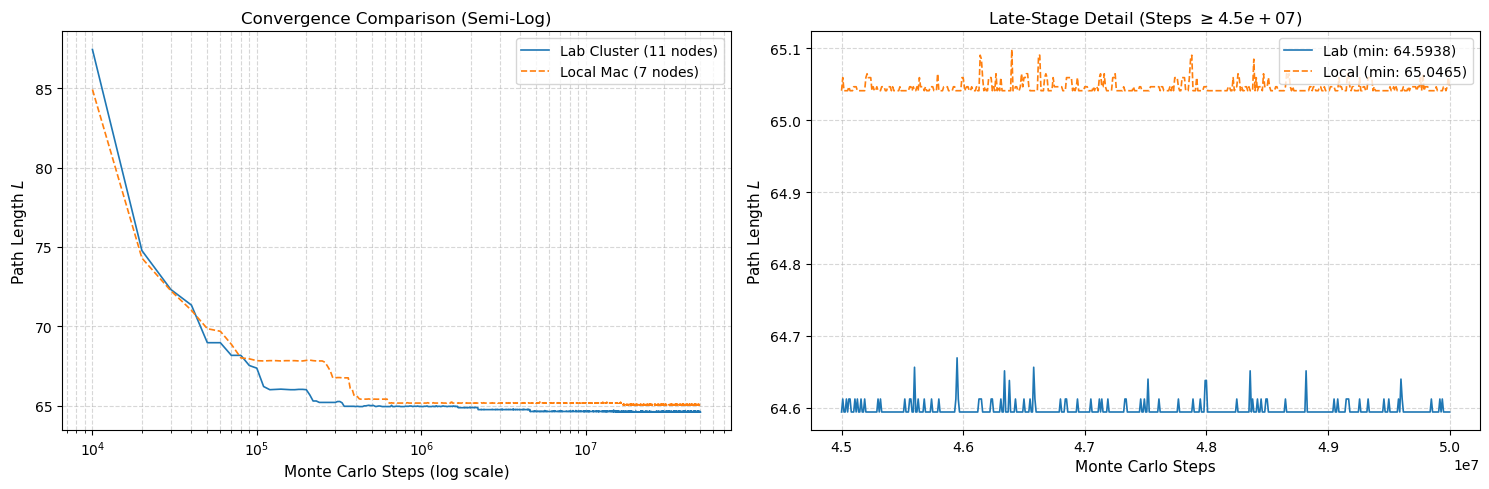

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Load remote lab data (11 nodes)
data_lab = np.loadtxt("OUTPUT_lab/L_rank0.dat")
steps_lab = data_lab[:, 0]
L_lab = data_lab[:, 1]

# 2. Load local run data (7 nodes)
data_local = np.loadtxt("OUTPUT/L_rank0.dat")
steps_local = data_local[:, 0]
L_local = data_local[:, 1]

# Masks to exclude step 0 from logarithmic scale
mask_lab = steps_lab > 0
steps_lab, L_lab = steps_lab[mask_lab], L_lab[mask_lab]

mask_local = steps_local > 0
steps_local, L_local = steps_local[mask_local], L_local[mask_local]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# ==========================================
# PLOT 1 (Left): Semi-Logarithmic Comparison
# ==========================================
ax1.plot(steps_lab, L_lab, color="#1f77b4", linewidth=1.2, label="Lab Cluster (11 nodes)")
ax1.plot(steps_local, L_local, color="#ff7f0e", linewidth=1.2, linestyle="--", label="Local Mac (7 nodes)")

ax1.set_xscale("log")
ax1.set_xlabel("Monte Carlo Steps (log scale)", fontsize=11)
ax1.set_ylabel(r"Path Length $L$", fontsize=11)
ax1.set_title("Convergence Comparison (Semi-Log)", fontsize=12)
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend(loc="upper right", frameon=True)

# ==========================================
# PLOT 2 (Right): Final Steps Zoom-In
# ==========================================
# Zooming in on the late-stage annealing phase (>= 4.5e7 steps)
zoom_threshold = 4.5e7

mask_zoom_lab = steps_lab >= zoom_threshold
mask_zoom_local = steps_local >= zoom_threshold

ax2.plot(steps_lab[mask_zoom_lab], L_lab[mask_zoom_lab], color="#1f77b4", linewidth=1.2, label=f"Lab (min: {L_lab[-1]:.4f})")
ax2.plot(steps_local[mask_zoom_local], L_local[mask_zoom_local], color="#ff7f0e", linewidth=1.2, linestyle="--", label=f"Local (min: {L_local[-1]:.4f})")

ax2.set_xlabel("Monte Carlo Steps", fontsize=11)
ax2.set_ylabel(r"Path Length $L$", fontsize=11)
ax2.set_title(rf"Late-Stage Detail (Steps $\geq {zoom_threshold:.1e}$)", fontsize=12)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

In [18]:
import os
import matplotlib.image as mpimg
from matplotlib.animation import FuncAnimation, PillowWriter

# 1. Load data from both simulations
data_lab = np.loadtxt("OUTPUT_lab/history_path.dat")  # 11 nodes
data_local = np.loadtxt("OUTPUT/history_path.dat")  # 7 nodes

steps_lab_all, x_lab_all, y_lab_all = (data_lab[:, 0], data_lab[:, 1], data_lab[:, 2],)
steps_loc_all, x_loc_all, y_loc_all = (data_local[:, 0], data_local[:, 1], data_local[:, 2],)

unique_steps_lab = np.unique(steps_lab_all)
unique_steps_loc = np.unique(steps_loc_all)

# Find synchronized steps saved across both runs
common_steps = np.intersect1d(unique_steps_lab, unique_steps_loc)
print(f"Synchronized frames to render: {len(common_steps)}")

# 2. Side-by-side figure setup
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# Map background setup (exact Wikimedia calibration)
bg_path = "italy.png"
has_bg = os.path.exists(bg_path)
if has_bg:
  bg_img = mpimg.imread(bg_path)
  img_extent = [6.2, 19.0, 35.3, 47.4]

for ax, panel_title in zip(
    [ax1, ax2], ["Lab Cluster (11 Nodes)", "Local Mac (7 Nodes)"]
):
  if has_bg:
    ax.imshow(bg_img, extent=img_extent, aspect="equal", alpha=0.55, zorder=1)
  ax.set_xlim(6.2, 19.0)
  ax.set_ylim(35.3, 47.4)
  ax.set_xlabel("Longitude (°E)", fontsize=10)
  ax.set_ylabel("Latitude (°N)", fontsize=10)
  ax.grid(True, linestyle="--", alpha=0.35)

# Graphical elements for left panel (Lab - 11 nodes)
(line_lab,) = ax1.plot([], [], color="#1f77b4", linewidth=1.3, marker="o", markersize=2.5, zorder=2, label="Path",)
start_lab = ax1.scatter([], [], color="navy", s=40, zorder=3, label="Initial Capital")
title_lab = ax1.text(0.5, 1.02, "", transform=ax1.transAxes, ha="center", fontsize=11, weight="bold",)
ax1.legend(loc="upper left", framealpha=0.8)

# Graphical elements for right panel (Local - 7 nodes)
(line_loc,) = ax2.plot([], [], color="#ff7f0e", linewidth=1.3, marker="o", markersize=2.5, zorder=2, label="Path",)
start_loc = ax2.scatter([], [], color="darkred", s=40, zorder=3, label="Initial Capital")
title_loc = ax2.text(0.5, 1.02, "", transform=ax2.transAxes, ha="center", fontsize=11, weight="bold",)
ax2.legend(loc="upper left", framealpha=0.8)

# 3. Path length calculation helper
def compute_length(x, y):
  dx = np.diff(x)
  dy = np.diff(y)
  return np.sum(np.sqrt(dx**2 + dy**2))

# 4. Frame update function
def update(frame_idx):
  step = common_steps[frame_idx]

  # Lab data update
  mask_lab = steps_lab_all == step
  x_l, y_l = x_lab_all[mask_lab], y_lab_all[mask_lab]
  line_lab.set_data(x_l, y_l)
  start_lab.set_offsets([[x_l[0], y_l[0]]])
  L_lab = compute_length(x_l, y_l)
  title_lab.set_text(f"Lab (11 nodes) | Step: {int(step):,} | L: {L_lab:.4f}")

  # Local data update
  mask_loc = steps_loc_all == step
  x_loc, y_loc = x_loc_all[mask_loc], y_loc_all[mask_loc]
  line_loc.set_data(x_loc, y_loc)
  start_loc.set_offsets([[x_loc[0], y_loc[0]]])
  L_loc = compute_length(x_loc, y_loc)
  title_loc.set_text(f"Local (7 nodes) | Step: {int(step):,} | L: {L_loc:.4f}")

  return line_lab, start_lab, title_lab, line_loc, start_loc, title_loc


anim = FuncAnimation(
    fig, update, frames=len(common_steps), interval=160, blit=False
)

# 5. Save GIF for GitHub rendering
output_gif = "OUTPUT/tsp_comparison_11vs7.gif"
writer = PillowWriter(fps=6)
anim.save(output_gif, writer=writer)
plt.close(fig)

print(f"Animation saved successfully as: {output_gif}")

Synchronized frames to render: 69
Animation saved successfully as: OUTPUT/tsp_comparison_11vs7.gif


### Parallel Tempering Evolution (11 Nodes vs 7 Nodes)

<p align="center">
  <img src="OUTPUT/tsp_comparison_11vs7.gif" alt="TSP Evolution 11 vs 7 nodes" width="95%"/>
</p>

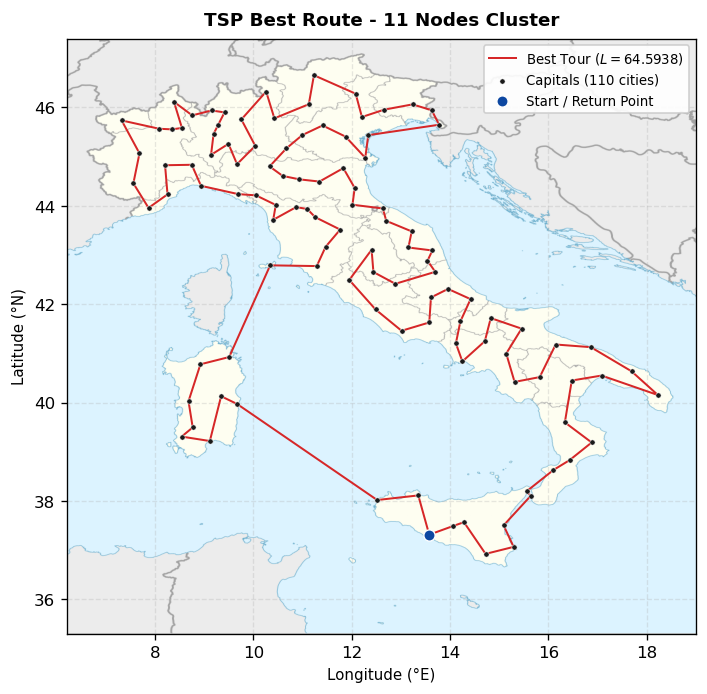

In [19]:
path = np.loadtxt("OUTPUT_lab/best_path.dat")
lon, lat = path[:, 0], path[:, 1]
if lon[0] != lon[-1] or lat[0] != lat[-1]:
  lon, lat = np.append(lon, lon[0]), np.append(lat, lat[0])
best_L = np.sum(np.sqrt(np.diff(lon) ** 2 + np.diff(lat) ** 2))

fig, ax = plt.subplots(figsize=(6, 7.5), dpi=120)

if os.path.exists("italy.png"):
  ax.imshow(
      mpimg.imread("italy.png"),
      extent=[6.2, 19.0, 35.3, 47.4],
      aspect="equal",
      alpha=0.6,
      zorder=1,
  )

# 3. Plot compatto su righe singole
ax.plot(lon, lat, color="#d62728", linewidth=1.2, zorder=2, label=rf"Best Tour ($L = {best_L:.4f}$)",)
ax.scatter(lon[:-1], lat[:-1], color="#1a1a1a", s=10, zorder=3, edgecolor="white", linewidth=0.3, label="Capitals (110 cities)",
)
ax.scatter(lon[0], lat[0], color="#0d47a1", s=45, zorder=4, edgecolor="white", linewidth=0.8, label="Start / Return Point",
)

ax.set_xlim(6.2, 19.0)
ax.set_ylim(35.3, 47.4)
ax.set_xlabel("Longitude (°E)", fontsize=9)
ax.set_ylabel("Latitude (°N)", fontsize=9)
ax.set_title(
    "TSP Best Route - 11 Nodes Cluster", fontsize=11, weight="bold", pad=8
)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper right", framealpha=0.9, fontsize=8)

plt.tight_layout()
plt.show()

The route shown above represents the best tour found across all simulations, achieving the global minimum path length:
$$L_{\min} = 64.5938$$

### **10.2**

### Parallel vs. Serial Algorithm

To establish a direct and consistent basis of comparison between the parallelized Parallel Tempering algorithm and the serial Genetic Algorithm (GA), the simulation parameters were matched as follows:

* **Time Evolution / Iterations:** The number of GA generations was set exactly equal to the total number of Monte Carlo Metropolis steps ($N_{\text{gen}} = N_{\text{steps}} = 5 \times 10^7$).
* **System Size / Sampling Population:** The population size of the Genetic Algorithm was matched directly to the number of MPI processes used in the parallel runs ($N_{\text{pop}} = N_{\text{nodes}} = 11$).

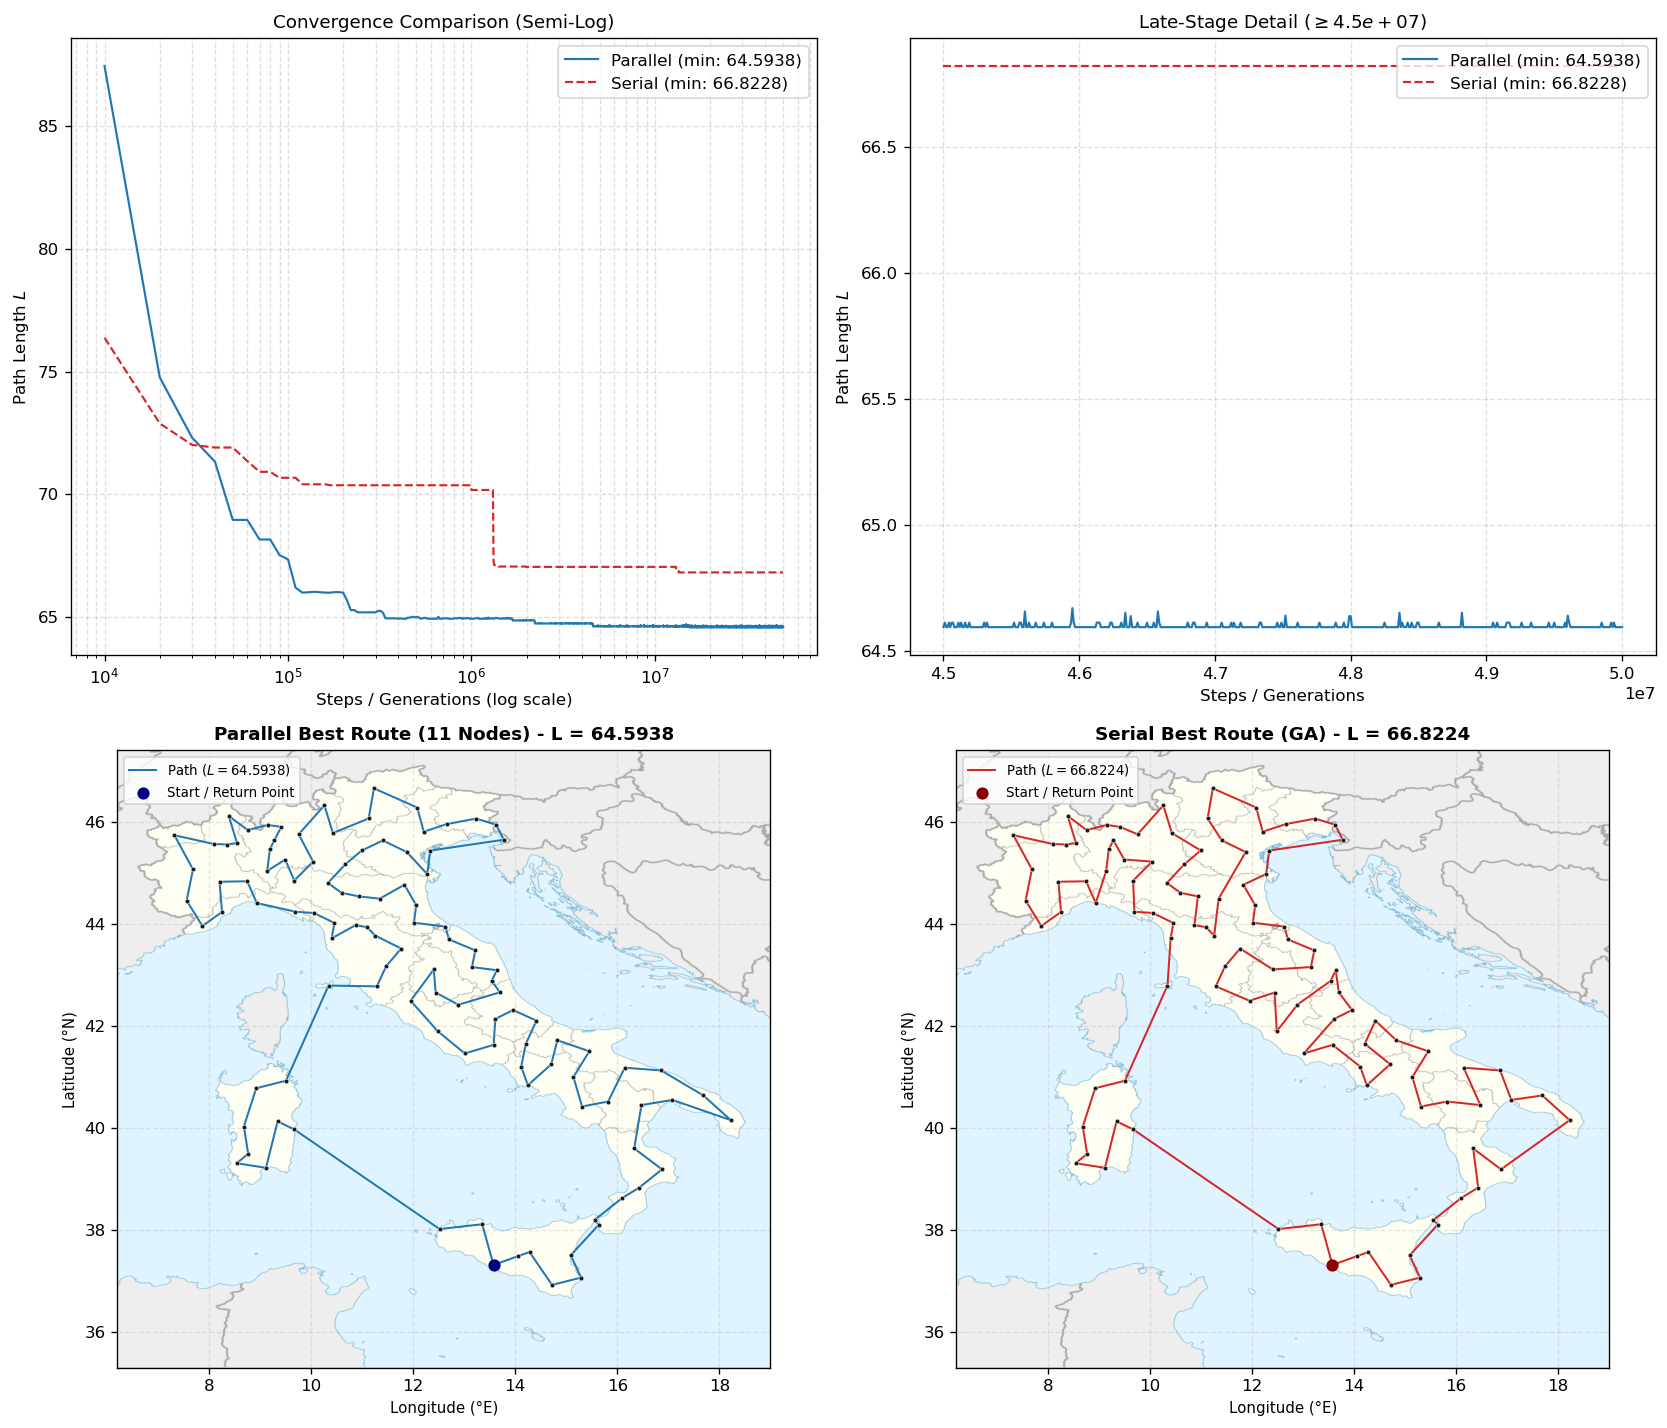

In [23]:
data_par = np.loadtxt("OUTPUT_lab/L_rank0.dat")
steps_par, L_par = data_par[:, 0], data_par[:, 1]
mask_par = steps_par > 0
steps_par, L_par = steps_par[mask_par], L_par[mask_par]

data_ser = np.loadtxt("NON_PAR/OUTPUT/italy_output.dat")
steps_ser, L_ser = data_ser[:, 0], data_ser[:, 1]
mask_ser = steps_ser > 0
steps_ser, L_ser = steps_ser[mask_ser], L_ser[mask_ser]

path_par = np.loadtxt("OUTPUT_lab/best_path.dat")
lon_par, lat_par = path_par[:, 0], path_par[:, 1]
if lon_par[0] != lon_par[-1] or lat_par[0] != lat_par[-1]:
  lon_par, lat_par = np.append(lon_par, lon_par[0]), np.append(
      lat_par, lat_par[0]
  )
best_L_par = np.sum(np.sqrt(np.diff(lon_par) ** 2 + np.diff(lat_par) ** 2))

path_ser = np.loadtxt("NON_PAR/OUTPUT/italy_path.dat")
lon_ser, lat_ser = path_ser[:, 0], path_ser[:, 1]
if lon_ser[0] != lon_ser[-1] or lat_ser[0] != lat_ser[-1]:
  lon_ser, lat_ser = np.append(lon_ser, lon_ser[0]), np.append(
      lat_ser, lat_ser[0]
  )
best_L_ser = np.sum(np.sqrt(np.diff(lon_ser) ** 2 + np.diff(lat_ser) ** 2))

fig, axs = plt.subplots(2, 2, figsize=(14, 12), dpi=120)

axs[0, 0].plot(
    steps_par,
    L_par,
    color="#1f77b4",
    linewidth=1.3,
    label=f"Parallel (min: {L_par[-1]:.4f})",
)
axs[0, 0].plot(
    steps_ser,
    L_ser,
    color="#d62728",
    linewidth=1.3,
    linestyle="--",
    label=f"Serial (min: {L_ser[-1]:.4f})",
)
axs[0, 0].set_xscale("log")
axs[0, 0].set_xlabel("Steps / Generations (log scale)", fontsize=10)
axs[0, 0].set_ylabel(r"Path Length $L$", fontsize=10)
axs[0, 0].set_title("Convergence Comparison (Semi-Log)", fontsize=11)
axs[0, 0].grid(True, which="both", linestyle="--", alpha=0.4)
axs[0, 0].legend(loc="upper right", frameon=True)

zoom_threshold = 4.5e7
mask_z_par = steps_par >= zoom_threshold
mask_z_ser = steps_ser >= zoom_threshold
axs[0, 1].plot(
    steps_par[mask_z_par],
    L_par[mask_z_par],
    color="#1f77b4",
    linewidth=1.3,
    label=f"Parallel (min: {L_par[-1]:.4f})",
)
axs[0, 1].plot(
    steps_ser[mask_z_ser],
    L_ser[mask_z_ser],
    color="#d62728",
    linewidth=1.3,
    linestyle="--",
    label=f"Serial (min: {L_ser[-1]:.4f})",
)
axs[0, 1].set_xlabel("Steps / Generations", fontsize=10)
axs[0, 1].set_ylabel(r"Path Length $L$", fontsize=10)
axs[0, 1].set_title(
    rf"Late-Stage Detail ($\geq {zoom_threshold:.1e}$)", fontsize=11
)
axs[0, 1].grid(True, linestyle="--", alpha=0.4)
axs[0, 1].legend(loc="upper right", frameon=True)

has_bg = os.path.exists("italy.png")
if has_bg:
  bg_img = mpimg.imread("italy.png")
  img_extent = [6.2, 19.0, 35.3, 47.4]

if has_bg:
  axs[1, 0].imshow(
      bg_img, extent=img_extent, aspect="equal", alpha=0.55, zorder=1
  )
axs[1, 0].plot(
    lon_par,
    lat_par,
    color="#1f77b4",
    linewidth=1.2,
    zorder=2,
    label=rf"Path ($L = {best_L_par:.4f}$)",
)
axs[1, 0].scatter(
    lon_par[:-1],
    lat_par[:-1],
    color="#1a1a1a",
    s=8,
    zorder=3,
    edgecolor="white",
    linewidth=0.3,
)
axs[1, 0].scatter(
    lon_par[0],
    lat_par[0],
    color="navy",
    s=40,
    zorder=4,
    label="Start / Return Point",
)
axs[1, 0].set_xlim(6.2, 19.0)
axs[1, 0].set_ylim(35.3, 47.4)
axs[1, 0].set_xlabel("Longitude (°E)", fontsize=9)
axs[1, 0].set_ylabel("Latitude (°N)", fontsize=9)
axs[1, 0].set_title(
    f"Parallel Best Route (11 Nodes) - L = {best_L_par:.4f}",
    fontsize=11,
    weight="bold",
)
axs[1, 0].grid(True, linestyle="--", alpha=0.3)
axs[1, 0].legend(loc="upper left", fontsize=8)

if has_bg:
  axs[1, 1].imshow(
      bg_img, extent=img_extent, aspect="equal", alpha=0.55, zorder=1
  )
axs[1, 1].plot(
    lon_ser,
    lat_ser,
    color="#d62728",
    linewidth=1.2,
    zorder=2,
    label=rf"Path ($L = {best_L_ser:.4f}$)",
)
axs[1, 1].scatter(
    lon_ser[:-1],
    lat_ser[:-1],
    color="#1a1a1a",
    s=8,
    zorder=3,
    edgecolor="white",
    linewidth=0.3,
)
axs[1, 1].scatter(
    lon_ser[0],
    lat_ser[0],
    color="darkred",
    s=40,
    zorder=4,
    label="Start / Return Point",
)
axs[1, 1].set_xlim(6.2, 19.0)
axs[1, 1].set_ylim(35.3, 47.4)
axs[1, 1].set_xlabel("Longitude (°E)", fontsize=9)
axs[1, 1].set_ylabel("Latitude (°N)", fontsize=9)
axs[1, 1].set_title(
    f"Serial Best Route (GA) - L = {best_L_ser:.4f}", fontsize=11, weight="bold"
)
axs[1, 1].grid(True, linestyle="--", alpha=0.3)
axs[1, 1].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

The convergence plots illustrate the optimization dynamics across the $5 \times 10^7$ steps/generations:

* **Solution Quality:** The parallel implementation (Parallel Tempering, 11 nodes) strictly outperforms the serial Genetic Algorithm, converging to a shorter path length ($L_{\min} = 64.5938$ versus $L_{\min} = 66.8228$). While the serial GA becomes trapped in a metastable local minimum after roughly $1.5 \times 10^6$ generations, the parallel tempering replicas continuously exchange configurations, enabling the low-temperature node to escape local traps.
* **Execution Time (Wall-Clock Time):** Beyond achieving a higher-quality minimum, the parallel code is significantly faster in total execution time. Distributing the $11$ replicas across dedicated MPI processes allows the parallel simulation to run concurrently, whereas the serial algorithm must evaluate sorting, crossover, and mutations sequentially across all individuals for every generation on a single core. This leads to a substantial reduction in wall-clock time for the parallel solver.